# 02 - Text to Embedding Baseline and Sample Generations

1. Tokenize captions with the SD 1.5 CLIP tokenizer
2. Encode with the SD 1.5 CLIP text encoder (ViT-L/14): per-token states [77, 768] and pooled [768]
3. Sanity-check the embedding space (similarity heatmap, intra vs inter category similarity, t-SNE)
4. Run 5 prompt-to-image tests with Stable Diffusion 1.5 and score them with CLIPScore
5. Show that generation is driven by these embeddings (generate from precomputed embeddings, interpolate between two prompts)

Requires notebook 01 to have produced `coco_clean.zip` on Drive.

## Setup

In [3]:
import os
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/t2i_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Must be set before importing transformers/diffusers so model weights cache on Drive
os.environ["HF_HUB_DISABLE_XET"] = "1"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
!rm -rf /content/hf_cache

In [5]:
!pip install -q diffusers accelerate

In [6]:
import torch

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > T4 GPU"
DEVICE = "cuda"
print(torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Tesla T4
VRAM: 15.6 GB


In [7]:
import json
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

LOCAL_ROOT = "/content/coco_clean"
TRAIN_DIR = f"{LOCAL_ROOT}/train"
DRIVE_DATA = f"{PROJECT_DIR}/data"
FIG_DIR = f"{PROJECT_DIR}/outputs/figures"
SAMPLE_DIR = f"{PROJECT_DIR}/outputs/samples"
for d in [FIG_DIR, SAMPLE_DIR]:
    os.makedirs(d, exist_ok=True)

SD_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_ID = "openai/clip-vit-large-patch14"
SEED = 42

if not os.path.exists(f"{TRAIN_DIR}/metadata.jsonl"):
    shutil.unpack_archive(f"{DRIVE_DATA}/coco_clean.zip", LOCAL_ROOT)

df = pd.read_json(f"{TRAIN_DIR}/metadata.jsonl", lines=True)
print(f"{len(df)} pairs")
df.head()

4189 pairs


,file_name,text,image_id,category,clip_score
0,images/000000190236.jpg,An office cubicle with four different types of...,190236,furniture,24.67
1,images/000000331352.jpg,This is an advanced toilet with a sink and con...,331352,furniture,26.07
2,images/000000517069.jpg,A woman sitting on a bench and a woman standin...,517069,outdoor,27.20
3,images/000000046378.jpg,Grey house cat devours a song bird on a door step,46378,animal,28.32
4,images/000000093437.jpg,An older man is wearing a funny hat in his din...,93437,person,27.64


## 1. Tokenization

In [8]:
from transformers import CLIPTokenizer, CLIPTextModel

tokenizer = CLIPTokenizer.from_pretrained(SD_ID, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(
    SD_ID, subfolder="text_encoder", torch_dtype=torch.float16
).to(DEVICE).eval()

example = df.text.iloc[0]
enc = tokenizer(example, padding="max_length", max_length=tokenizer.model_max_length, truncation=True)
n_real = sum(enc.attention_mask)

print(example)
print(f"real tokens (incl. BOS/EOS): {n_real}, padded length: {len(enc.input_ids)}")
print(tokenizer.convert_ids_to_tokens(enc.input_ids[:n_real]))

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An office cubicle with four different types of computers
real tokens (incl. BOS/EOS): 13, padded length: 77
['<|startoftext|>', 'an</w>', 'office</w>', 'cubic', 'le</w>', 'with</w>', 'four</w>', 'different</w>', 'types</w>', 'of</w>', 'compu', 'ters</w>', '<|endoftext|>']


## 2. Text encoding

SD 1.5 conditions the UNet on `last_hidden_state` (one 768-d vector per token, 77 tokens) via cross-attention. The pooled output (EOS token state) is a single sentence-level vector, used here for analysis only.

In [9]:
@torch.no_grad()
def encode(texts):
    ids = tokenizer(texts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    out = text_encoder(ids)  # SD 1.5 does not pass an attention mask; match that
    return out.last_hidden_state, out.pooler_output

hidden, pooled = encode([example])
print("last_hidden_state:", tuple(hidden.shape))
print("pooler_output:    ", tuple(pooled.shape))

last_hidden_state: (1, 77, 768)
pooler_output:     (1, 768)


In [10]:
from tqdm.auto import tqdm

BATCH = 128
pooled_all = []
for i in tqdm(range(0, len(df), BATCH)):
    _, p = encode(df.text.iloc[i:i + BATCH].tolist())
    pooled_all.append(p.float().cpu().numpy())

pooled_all = np.concatenate(pooled_all)
np.save(f"{DRIVE_DATA}/pooled_text_embeddings.npy", pooled_all)
emb = pooled_all / np.linalg.norm(pooled_all, axis=1, keepdims=True)
print(emb.shape)

  0%|          | 0/33 [00:00<?, ?it/s]

(4189, 768)


## 3. Embedding sanity checks

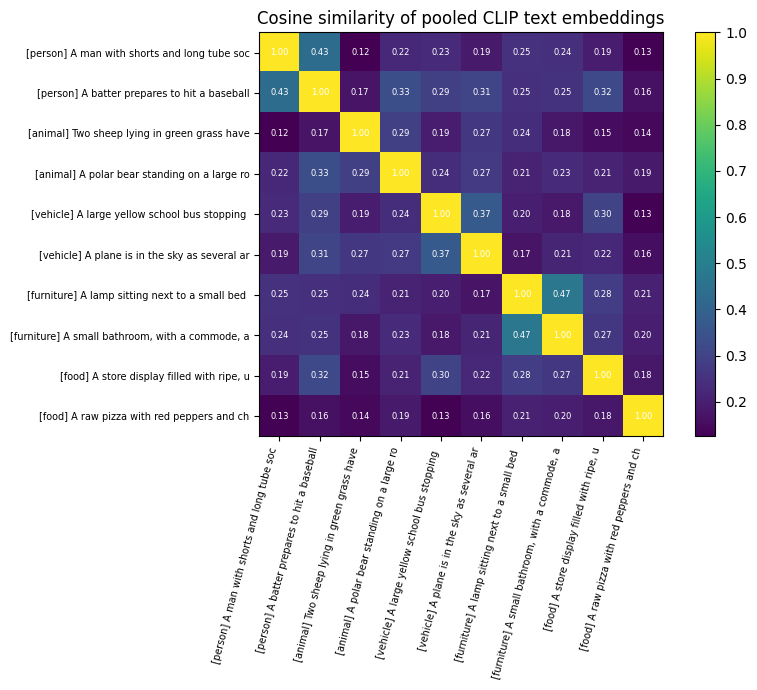

In [11]:
top_cats = df.category.value_counts().index[:5]
demo = pd.concat([df[df.category == c].sample(2, random_state=SEED) for c in top_cats])
sim = emb[demo.index] @ emb[demo.index].T
labels = [f"[{c}] {t[:35]}" for c, t in zip(demo.category, demo.text)]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(sim, cmap="viridis")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=75, ha="right", fontsize=7)
ax.set_yticklabels(labels, fontsize=7)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white")
fig.colorbar(im)
ax.set_title("Cosine similarity of pooled CLIP text embeddings")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/text_similarity_heatmap.png", dpi=150)
plt.show()

In [12]:
sample = df.sample(min(2000, len(df)), random_state=SEED)
S = emb[sample.index] @ emb[sample.index].T
cats = sample.category.values
same = cats[:, None] == cats[None, :]
off_diag = ~np.eye(len(S), dtype=bool)

intra = S[same & off_diag].mean()
inter = S[~same].mean()
print(f"mean cosine, same category:      {intra:.3f}")
print(f"mean cosine, different category: {inter:.3f}")
print(f"gap: {intra - inter:.3f}  (positive gap = embeddings carry content information)")

mean cosine, same category:      0.295
mean cosine, different category: 0.216
gap: 0.079  (positive gap = embeddings carry content information)


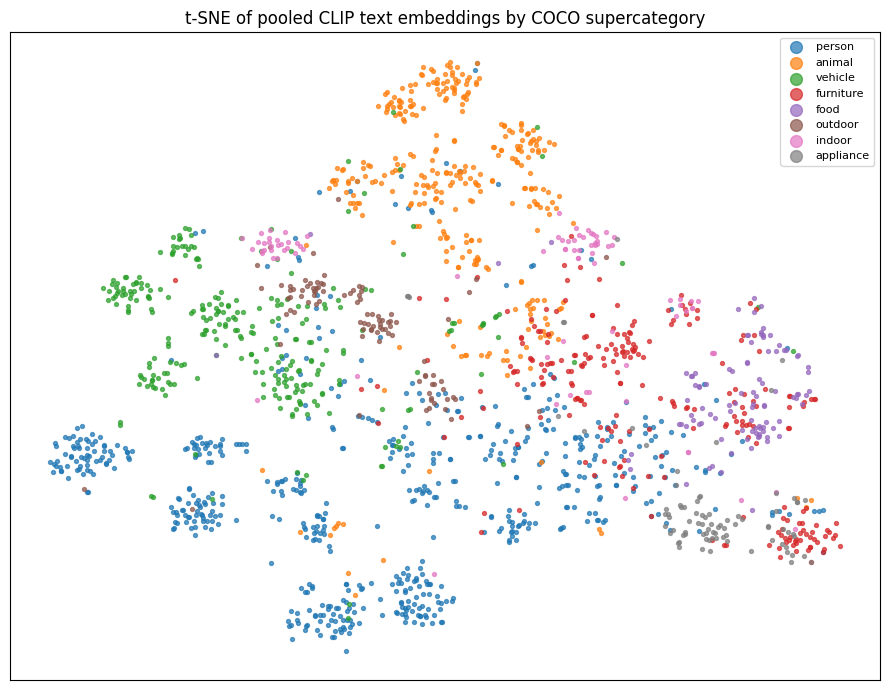

In [13]:
from sklearn.manifold import TSNE

keep_cats = df.category.value_counts().index[:8]
tsne_df = sample[sample.category.isin(keep_cats)]
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(emb[tsne_df.index])

fig, ax = plt.subplots(figsize=(9, 7))
for c in keep_cats:
    m = (tsne_df.category == c).values
    ax.scatter(xy[m, 0], xy[m, 1], s=8, alpha=0.7, label=c)
ax.legend(markerscale=3, fontsize=8)
ax.set_title("t-SNE of pooled CLIP text embeddings by COCO supercategory")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/text_embedding_tsne.png", dpi=150)
plt.show()

In [14]:
del text_encoder
torch.cuda.empty_cache()

## 4. Prompt to image test runs (Stable Diffusion 1.5)

In [15]:
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

pipe = StableDiffusionPipeline.from_pretrained(SD_ID, torch_dtype=torch.float16, variant="fp16").to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)

STEPS = 25
GUIDANCE = 7.5

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Prompt design: 2 captions from the cleaned dataset (in-distribution, with a real reference image), plus 3 known weak spots for SD 1.5. Counting, spatial relations, and unusual compositions are where failures are expected; documenting them now gives later milestones something measurable to improve.

In [16]:
ds_rows = df.sample(2, random_state=SEED)
test_prompts = [
    {"type": "dataset", "prompt": ds_rows.text.iloc[0], "ref_file": ds_rows.file_name.iloc[0]},
    {"type": "dataset", "prompt": ds_rows.text.iloc[1], "ref_file": ds_rows.file_name.iloc[1]},
    {"type": "counting", "prompt": "Three red apples on a wooden table", "ref_file": None},
    {"type": "spatial", "prompt": "A cat sitting to the left of a dog on a sofa", "ref_file": None},
    {"type": "compositional", "prompt": "A giraffe wearing a business suit riding a bicycle in a city street", "ref_file": None},
]

generated = []
for i, t in enumerate(test_prompts):
    gen = torch.Generator(DEVICE).manual_seed(SEED)
    start = time.time()
    out = pipe(t["prompt"], num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=gen)
    t["seconds"] = round(time.time() - start, 2)
    t["nsfw_flag"] = bool(out.nsfw_content_detected[0])
    img = out.images[0]
    img.save(f"{SAMPLE_DIR}/sample_{i + 1}_{t['type']}.png")
    generated.append(img)
    print(f"{i + 1}. [{t['type']}] {t['seconds']}s  {t['prompt']}")

1. [dataset] 6.56s  A woman with a hat, tie and striped halter smoking a long cigarette
2. [dataset] 4.92s  A hot dog vendor sits outside a famous building in the city
3. [counting] 4.95s  Three red apples on a wooden table
4. [spatial] 4.97s  A cat sitting to the left of a dog on a sofa
5. [compositional] 5.01s  A giraffe wearing a business suit riding a bicycle in a city street


In [18]:
from transformers import CLIPModel, CLIPProcessor

scorer = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=torch.float16).to(DEVICE).eval()
scorer_proc = CLIPProcessor.from_pretrained(CLIP_ID)

@torch.no_grad()
def clip_score(imgs, texts):
    inputs = scorer_proc(text=texts, images=imgs, return_tensors="pt",
                         padding=True, truncation=True).to(DEVICE)
    out = scorer(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
                 pixel_values=inputs["pixel_values"].half())
    i = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    t = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return (100 * (i * t).sum(dim=-1).clamp(min=0)).float().cpu().tolist()

gen_scores = clip_score(generated, [t["prompt"] for t in test_prompts])
for t, s in zip(test_prompts, gen_scores):
    t["clip_score_generated"] = round(s, 2)
    if t["ref_file"]:
        ref = Image.open(f"{TRAIN_DIR}/{t['ref_file']}").convert("RGB")
        t["clip_score_real"] = round(clip_score([ref], [t["prompt"]])[0], 2)

results = pd.DataFrame(test_prompts).assign(seed=SEED, steps=STEPS, guidance=GUIDANCE)
results.to_csv(f"{SAMPLE_DIR}/results.csv", index=False)
results[["type", "prompt", "clip_score_generated", "clip_score_real", "seconds"]]

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

,type,prompt,clip_score_generated,clip_score_real,seconds
0,dataset,"A woman with a hat, tie and striped halter smo...",30.77,26.39,6.56
1,dataset,A hot dog vendor sits outside a famous buildin...,28.34,30.73,4.92
2,counting,Three red apples on a wooden table,24.38,NaN,4.95
3,spatial,A cat sitting to the left of a dog on a sofa,32.31,NaN,4.97
4,compositional,A giraffe wearing a business suit riding a bic...,32.12,NaN,5.01


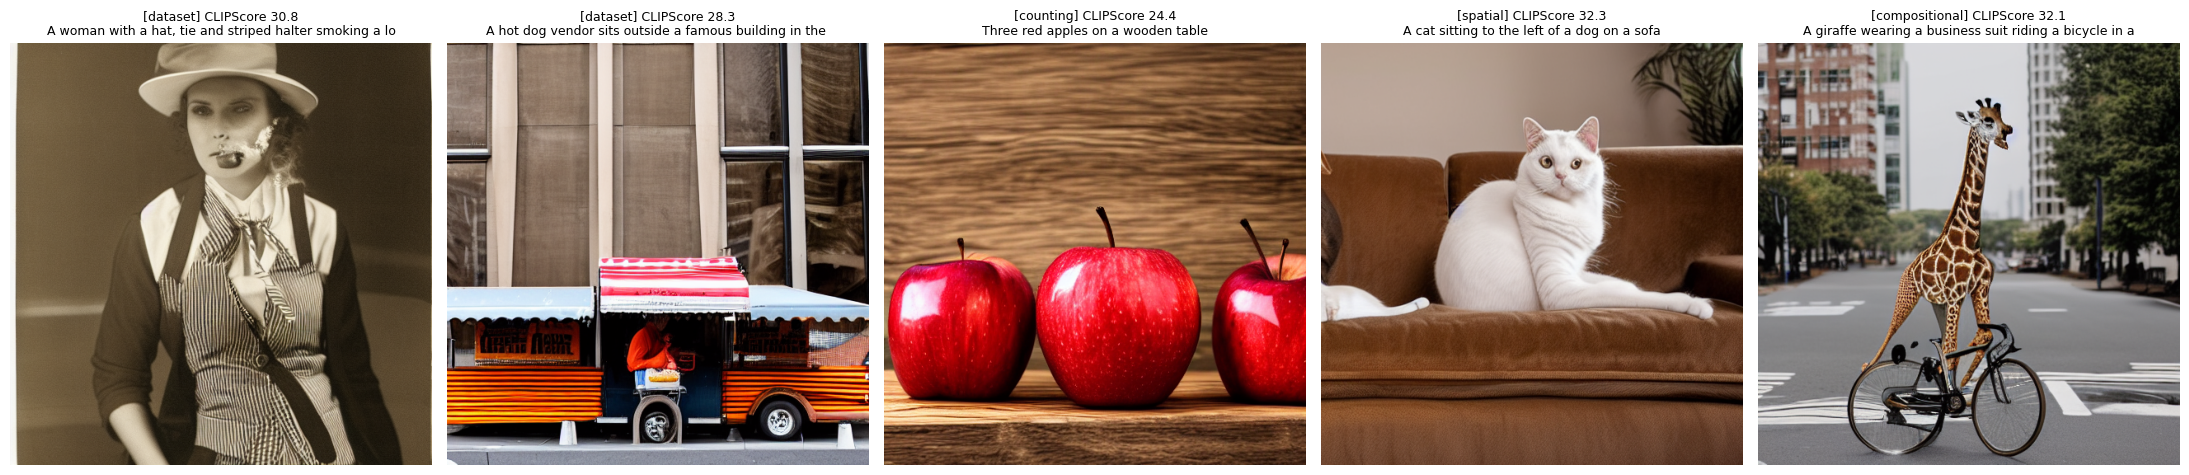

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5.5))
for ax, img, t in zip(axes, generated, test_prompts):
    ax.imshow(img)
    ax.set_title(f"[{t['type']}] CLIPScore {t['clip_score_generated']:.1f}\n{t['prompt'][:55]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/sample_generations.png", dpi=150)
plt.show()

## 5. Generation is driven by the text embeddings

(a) Encode a prompt manually and pass `prompt_embeds` instead of text. With the same seed the image should match the text-prompt run.
(b) Linearly interpolate between two prompt embeddings. A smooth visual transition shows the UNet is responding to the embedding space itself.

In [20]:
@torch.no_grad()
def embed_prompt(text):
    ids = pipe.tokenizer(text, padding="max_length", max_length=pipe.tokenizer.model_max_length,
                         truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    return pipe.text_encoder(ids)[0]

gen = torch.Generator(DEVICE).manual_seed(SEED)
from_embeds = pipe(prompt_embeds=embed_prompt(test_prompts[0]["prompt"]), num_inference_steps=STEPS,
                   guidance_scale=GUIDANCE, generator=gen).images[0]

diff = np.abs(np.asarray(from_embeds, dtype=np.float32) - np.asarray(generated[0], dtype=np.float32)).mean()
print(f"mean abs pixel difference vs text-prompt run: {diff:.2f} (0-255 scale; near 0 = same conditioning)")

mean abs pixel difference vs text-prompt run: 0.00 (0-255 scale; near 0 = same conditioning)


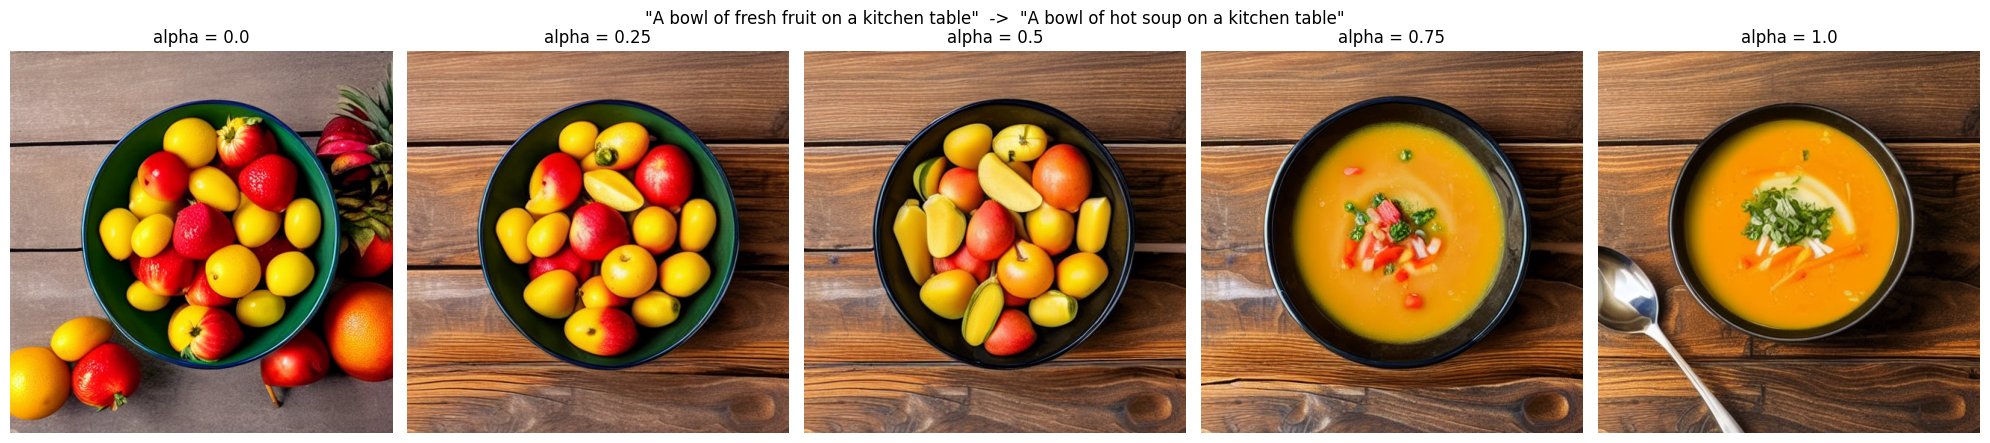

In [21]:
prompt_a = "A bowl of fresh fruit on a kitchen table"
prompt_b = "A bowl of hot soup on a kitchen table"
emb_a, emb_b = embed_prompt(prompt_a), embed_prompt(prompt_b)

alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
interp = []
for a in alphas:
    gen = torch.Generator(DEVICE).manual_seed(SEED)
    e = (1 - a) * emb_a + a * emb_b
    interp.append(pipe(prompt_embeds=e, num_inference_steps=STEPS,
                       guidance_scale=GUIDANCE, generator=gen).images[0])

fig, axes = plt.subplots(1, len(alphas), figsize=(20, 4.5))
for ax, img, a in zip(axes, interp, alphas):
    ax.imshow(img)
    ax.set_title(f"alpha = {a}")
    ax.axis("off")
fig.suptitle(f'"{prompt_a}"  ->  "{prompt_b}"')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/embedding_interpolation.png", dpi=150)
plt.show()

In [22]:
print(open(f"{DRIVE_DATA}/stats.json").read())

{
  "images_total": 5000,
  "captions_total": 25014,
  "dropped_no_valid_caption": 0,
  "dropped_image_filter": 74,
  "dropped_clip_filter": 737,
  "clip_threshold": 22.34,
  "final_pairs": 4189
}


## Report checklist

- Dataset funnel and final pair count: `data/stats.json` (notebook 01)
- CLIPScore histogram: `outputs/figures/clip_score_hist.png`
- Embedding shapes, intra vs inter category similarity, t-SNE figure
- 5 sample generations with CLIPScore: `outputs/figures/sample_generations.png` and `outputs/samples/results.csv`
- Comment on failures in the counting / spatial / compositional prompts; that is the baseline later milestones should improve
- Copy `outputs/` from Drive into the repo before committing (keep `data/` out of git)